# Étape 5 – Identification des thématiques

**Questions** : quels grands sujets se dégagent des titres ? Peut-on les retrouver de façon stable avec deux méthodes différentes ? Que valent ces regroupements ?

**Méthodes comparées**
1. **TF-IDF** : chaque titre devient un vecteur où un mot pèse d'autant plus qu'il est fréquent dans le titre (TF, atténué par un log) et rare dans le corpus (IDF).
2. **K-Means sur TF-IDF réduit par LSA** : les titres sont regroupés en k groupes par distance cosinus. La réduction par SVD tronquée (100 dimensions) débruite une matrice de ≈ 3 000 mots très creuse.
3. **LDA** (*Latent Dirichlet Allocation*) : modèle probabiliste où chaque titre est un mélange de thèmes et chaque thème une distribution sur les mots. Il travaille sur des comptes de mots, pas sur du TF-IDF.

**Évaluer sans vérité terrain.** Nous n'avons pas d'étiquettes de thèmes. On combine (a) des métriques internes (silhouette, cohérence NPMI, stabilité entre graines aléatoires),
(b) une **référence externe partielle** : les rubriques éditoriales du Progrès (faits-divers-justice, economie, societe…), disponibles pour 44 % du corpus, et (c) la lecture des termes et des titres.
Ces rubriques ne sont pas « la » bonne partition (un thème comme « mobilisation lycéenne » traverse plusieurs rubriques) mais elles disent si les groupes sont éditorialement cohérents.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
MEDIA_ORDER = ["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]
MEDIA_COLORS = dict(zip(MEDIA_ORDER, sns.color_palette("deep")[:4]))

from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score
from sklearn.cluster import KMeans
from src.preprocessing.text_cleaning import add_token_columns
from src.modeling import topics as T

SEED = 0
corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
df = add_token_columns(corpus[corpus["in_analysis"]]).reset_index(drop=True)
docs = T.docs_from_tokens(df["tokens_lemma"])
keep = np.array([len(d.split()) >= 2 for d in docs])           # titres avec au moins 2 lemmes
print(f"{len(df):,} titres ; {(~keep).sum()} avec moins de 2 lemmes écartés des modèles")
df, docs = df[keep].reset_index(drop=True), [d for d, k in zip(docs, keep) if k]
section = df["section"].where(df["media_name"] == "Le Progrès")        # référence externe : rubriques du Progrès
print(f"Référence externe disponible pour {section.notna().sum():,} titres")

4,936 titres ; 7 avec moins de 2 lemmes écartés des modèles
Référence externe disponible pour 2,170 titres


## 1. Représentation TF-IDF

In [2]:
vec, X = T.make_tfidf(docs, min_df=3, max_df=0.4)
vocab = np.array(vec.get_feature_names_out())
print(f"Matrice {X.shape[0]:,} titres × {X.shape[1]:,} termes ; densité {X.nnz / np.prod(X.shape):.3%} ; {X.nnz / X.shape[0]:.1f} termes non nuls par titre")
mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
print("Termes au TF-IDF moyen le plus élevé :", ", ".join(vocab[mean_tfidf.argsort()[::-1][:25]]))
for i in [3, 400, 2000]:
    row = X[i].toarray().ravel(); top = row.argsort()[::-1][:5]
    print(f"\n« {df.title_clean[i][:100]} »\n   termes les plus caractéristiques : " + ", ".join(f"{vocab[j]} ({row[j]:.2f})" for j in top))

Matrice 4,929 titres × 2,528 termes ; densité 0.218% ; 5.5 termes non nuls par titre
Termes au TF-IDF moyen le plus élevé : homme, villeurbanne, blessé, manifestation, personne, métropole, lycéen, euro, incendie, violence, auvergne-rhône-alpes, interpeller, attendu, beaujolais, feu, lycée, ville, jeune, france, mort, degré, femme, vie, prison, voiture

« J'ai testé pour vous : une jolie balade, la boucle de Flassieu à Chaponnay »
   termes les plus caractéristiques : tester (1.00), œuvre (0.00), espoir (0.00), examen (0.00), ex-compagne (0.00)

« Soleil, orage et pluie : une météo changeante attendue à Lyon »
   termes les plus caractéristiques : soleil (0.50), pluie (0.49), météo (0.44), attendre (0.40), orage (0.39)

« À 16 ans, il crée un site pour mieux comprendre le Parlement européen »
   termes les plus caractéristiques : comprendre (0.56), européen (0.52), site (0.48), créer (0.44), œuvre (0.00)


## 2. K-Means : choix du nombre de groupes
On teste k de 4 à 30. Trois signaux : la **silhouette** (cohésion/séparation, sur des textes courts elle reste faible), la **stabilité** (ARI entre trois graines aléatoires : un partitionnement qui change à chaque tirage n'est pas fiable)
et l'**AMI avec les rubriques du Progrès**. Il n'existe pas de k « optimal » : on cherche un compromis lisible.

LSA : 100 composantes, variance expliquée 22.1%


,silhouette,stabilité (ARI),AMI vs rubriques
k,,,
4,0.032,0.544,0.089
6,0.044,0.314,0.068
8,0.055,0.307,0.096
10,0.058,0.289,0.109
12,0.069,0.345,0.083
14,0.083,0.245,0.119
16,0.094,0.322,0.098
18,0.103,0.282,0.098
20,0.113,0.218,0.105


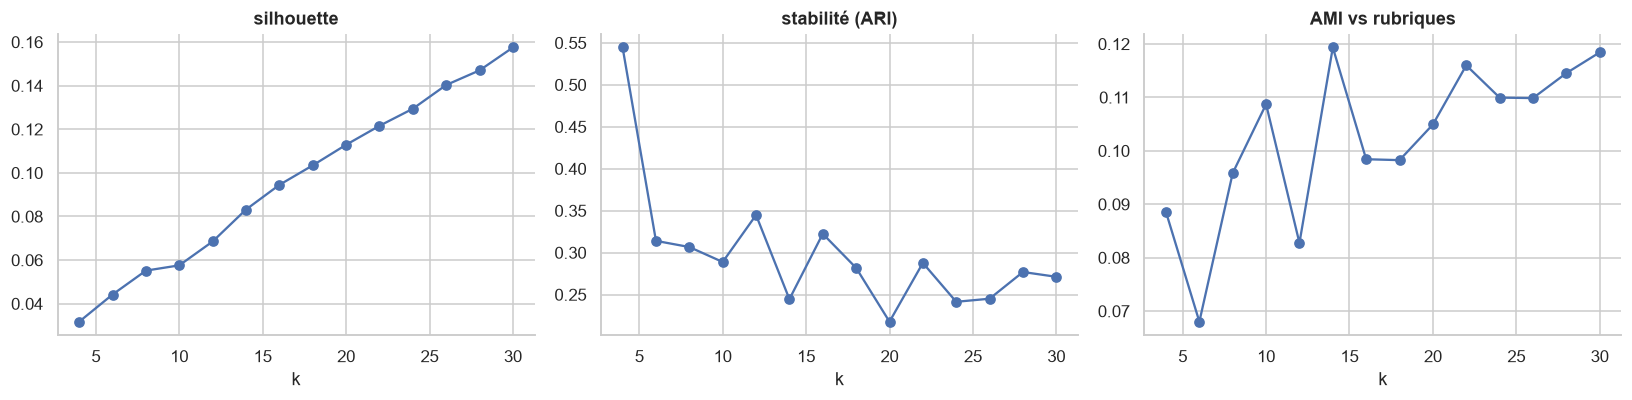

In [3]:
Z, svd = T.lsa(X, n_components=100, seed=SEED)
print(f"LSA : 100 composantes, variance expliquée {svd.explained_variance_ratio_.sum():.1%}")
scan = T.kmeans_scan(Z, range(4, 31, 2), seeds=(0, 1, 2), ref_labels=section)
scan.round(3).to_csv(TAB / "05_kmeans_choix_k.csv"); display(scan.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, scan.columns):
    ax.plot(scan.index, scan[col], marker="o"); ax.set(title=col, xlabel="k")
plt.tight_layout(); fig.savefig(FIG / "05_kmeans_choix_k.png", bbox_inches="tight"); plt.show()

In [4]:
K_KM = 14
km = KMeans(n_clusters=K_KM, n_init=20, random_state=SEED).fit(Z)
df["km"] = km.labels_
km_terms = T.top_terms_per_cluster(X, km.labels_, vocab, n=10)
km_tab = pd.DataFrame({"cluster": c, "titres": int((km.labels_ == c).sum()), "termes": ", ".join(w)} for c, w in km_terms.items()).set_index("cluster")
km_tab

,titres,termes
cluster,,
0,73,"travaux, route, prochain, circulation, pont, condrieu, fermé, attendu, plusieurs, réaliser"
1,888,"personne, blessé, femme, accident, feu, mort, pompier, voiture, nuit, vol"
2,205,"homme, interpeller, blessé, suspect, jeune, balle, poignarder, condamné, mort, personne"
3,427,"manifestation, lycéen, lycée, mobilisation, prison, violence, interdire, rassemblement, ferme, mouvement"
4,196,"auvergne-rhône-alpes, france, vigilance, département, orage, canicule, orange, tour, forêt, feu"
5,917,"vie, quartier, ancien, entreprise, histoire, école, association, depuis, social, devenir"
6,111,"incendie, hectare, mobiliser, brûlé, déclarer, pompier, déchet, violent, détruire, entreprise"
7,134,"face, sécheresse, eau, crise, agriculteur, état, solution, ouest, climatique, professionnel"
8,281,"euro, métropole, ville, million, aide, hôtel, aulas, débloquer, violence, financier"


## 3. LDA : choix du nombre de thèmes

,cohérence NPMI (moyenne),perplexité (test)
k,,
6,-0.174,17586.726
8,-0.248,24379.678
10,-0.230,30669.172
12,-0.244,38809.081
14,-0.279,43595.021
16,-0.238,52212.248
20,-0.322,72576.394


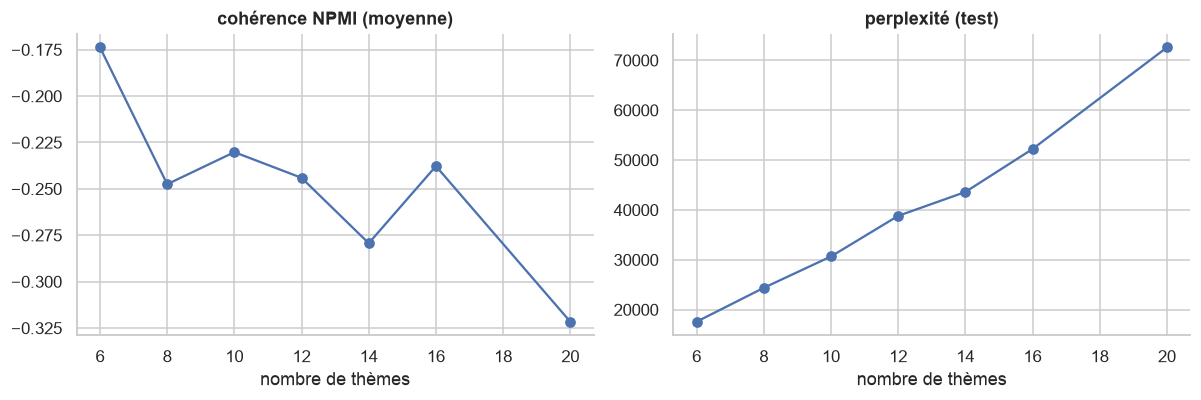

In [5]:
vec_c, Xc = T.make_counts(docs, min_df=3, max_df=0.3)
vocab_c = np.array(vec_c.get_feature_names_out())
lda_scan, lda_models = T.lda_scan(Xc, vocab_c, ks=[6, 8, 10, 12, 14, 16, 20], seed=SEED)
lda_scan.round(3).to_csv(TAB / "05_lda_choix_k.csv"); display(lda_scan.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, lda_scan.columns):
    ax.plot(lda_scan.index, lda_scan[col], marker="o"); ax.set(title=col, xlabel="nombre de thèmes")
plt.tight_layout(); fig.savefig(FIG / "05_lda_choix_k.png", bbox_inches="tight"); plt.show()

In [6]:
K_LDA = 6
lda = lda_models[K_LDA]
theta = lda.transform(Xc)                                        # mélange de thèmes de chaque titre
df["lda"] = theta.argmax(axis=1); df["lda_prob"] = theta.max(axis=1)
lda_terms = T.lda_topics(lda, vocab_c, n=10)
lda_tab = pd.DataFrame({"thème": t, "titres (dominant)": int((df.lda == t).sum()), "probabilité moyenne": round(float(df.loc[df.lda == t, "lda_prob"].mean()), 2), "termes": ", ".join(w)} for t, w in lda_terms.items()).set_index("thème")
lda_tab

,titres (dominant),probabilité moyenne,termes
thème,,,
0,850,0.67,"euro, million, métropole, parc, métro, accident, tête, ville, france, travaux"
1,717,0.67,"auvergne-rhône-alpes, attendu, département, degré, vigilance, beaujolais, orage, île, presqu, canicule"
2,854,0.67,"homme, interpeller, personne, blessé, suspect, villeurbanne, jeune, coup, voiture, retour"
3,812,0.68,"tour, lycéen, porte, grève, france, festival, villeurbanne, manifestation, mobilisation, prix"
4,857,0.68,"violence, manifestation, municipal, lycée, dénoncer, doucet, grégory, maire, lycéen, sexuel"
5,839,0.67,"prison, condamné, incendie, pompier, victime, ferme, place, mort, pillage, vol"


## 4. Comparaison des deux méthodes

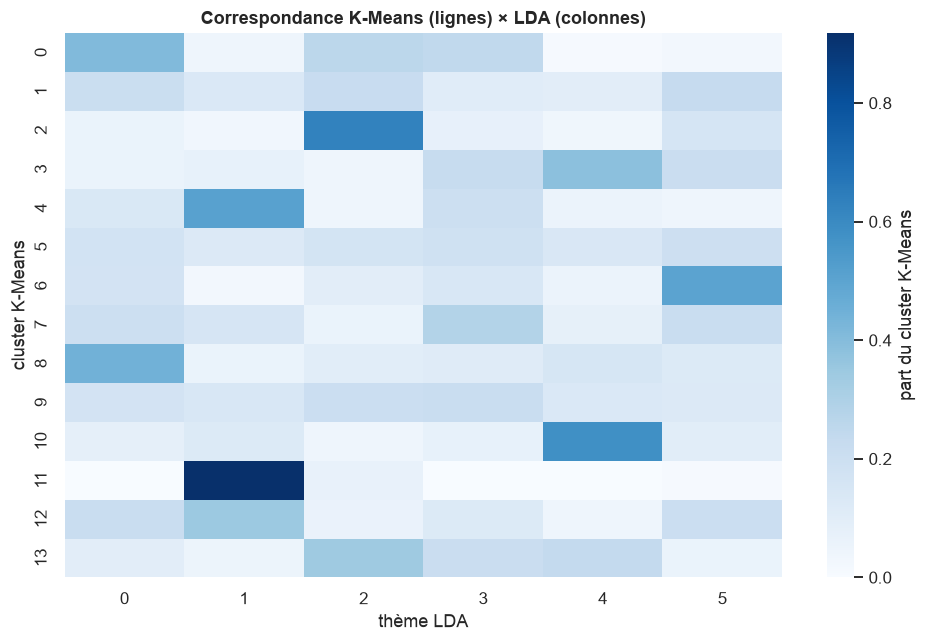

Accord entre les deux partitions : ARI = 0.033, AMI = 0.085
Accord avec les rubriques du Progrès (AMI) : K-Means 0.119 | LDA 0.032
Part des titres dont le thème LDA dominant a une probabilité > 0,5 : 79.5%


In [7]:
ct = pd.crosstab(df["km"], df["lda"], normalize="index")
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ct, cmap="Blues", ax=ax, cbar_kws={"label": "part du cluster K-Means"}); ax.set(title="Correspondance K-Means (lignes) × LDA (colonnes)", xlabel="thème LDA", ylabel="cluster K-Means")
plt.tight_layout(); fig.savefig(FIG / "05_kmeans_vs_lda.png", bbox_inches="tight"); plt.show()
ref = section.notna().values
print(f"Accord entre les deux partitions : ARI = {adjusted_rand_score(df.km, df.lda):.3f}, AMI = {adjusted_mutual_info_score(df.km, df.lda):.3f}")
print(f"Accord avec les rubriques du Progrès (AMI) : K-Means {adjusted_mutual_info_score(section[ref], df.km[ref]):.3f} | LDA {adjusted_mutual_info_score(section[ref], df.lda[ref]):.3f}")
print(f"Part des titres dont le thème LDA dominant a une probabilité > 0,5 : {(df.lda_prob > 0.5).mean():.1%}")

## 5. Lecture des thèmes

In [8]:
LABELS_KM = {0: "Travaux et circulation", 1: "Accidents, incendies et faits divers du quotidien", 2: "Violences, interpellations et justice pénale",
 3: "Mobilisation lycéenne et manifestations", 4: "Vigilance météo et alertes régionales", 5: "Vie locale, associations, entreprises, école",
 6: "Incendies de grande ampleur", 7: "Sécheresse, climat et agriculture", 8: "Finances publiques et projets métropolitains",
 9: "Culture, festivals, rentrée (groupe fourre-tout)", 10: "Politique municipale et élections", 11: "Météo locale (prévisions)",
 12: "Beaujolais, vigne et vendanges", 13: "Fusillades et trafic à Villeurbanne"}
LABELS_LDA = {0: "Finances, aménagement et transports", 1: "Météo, vigilance et territoires", 2: "Faits divers et interpellations",
 3: "Mobilisation, grèves, festivals (mixte)", 4: "Politique municipale, violences, lycées (mixte)", 5: "Justice, prison, incendies, pillages"}
df["km_label"] = df["km"].map(LABELS_KM); df["lda_label"] = df["lda"].map(LABELS_LDA)
km_tab["libellé"] = km_tab.index.map(LABELS_KM); lda_tab["libellé"] = lda_tab.index.map(LABELS_LDA)
km_tab.to_csv(TAB / "05_themes_kmeans.csv"); lda_tab.to_csv(TAB / "05_themes_lda.csv")
for t in lda_tab.index:
    print(f"\n— LDA {t} : {LABELS_LDA[t]}"); print(df[(df.lda == t)].sort_values("lda_prob", ascending=False)["title_clean"].head(3).str.slice(0, 110).to_string(index=False))


— LDA 0 : Finances, aménagement et transports
« Le parc des Balmes ne prend tout son sens que s'il descend au Vieux Lyon », Thomas Rudigoz demande à Grégory
« Large assise financière » mais alerte sur le Sytral : ce que révèle l'audit commandé par Véronique Sarselli 
       Ski : un Pass Scolaire Loisirs unique pour les jeunes du Pays du Mont-Blanc et de la vallée de Chamonix

— LDA 1 : Météo, vigilance et territoires
Mobilisation à Lyon : la façade d'un lycée incendiée, tirs de mortiers, collégien blessé… la matinée démarre s
Mobilisation à Lyon : la façade d'un lycée incendiée, tirs de mortiers, collégien blessé… la matinée démarre s
Mobilisation à Lyon : la façade d'un lycée incendiée, tirs de mortiers, collégien blessé… la matinée démarre s

— LDA 2 : Faits divers et interpellations
Thomas Gaubert nommé président du pôle formation de l'Union des industries et des métiers de la métallurgie Lo
Projets au point mort et façades dégradées : fermés depuis 10 ans, que deviennent les ciné

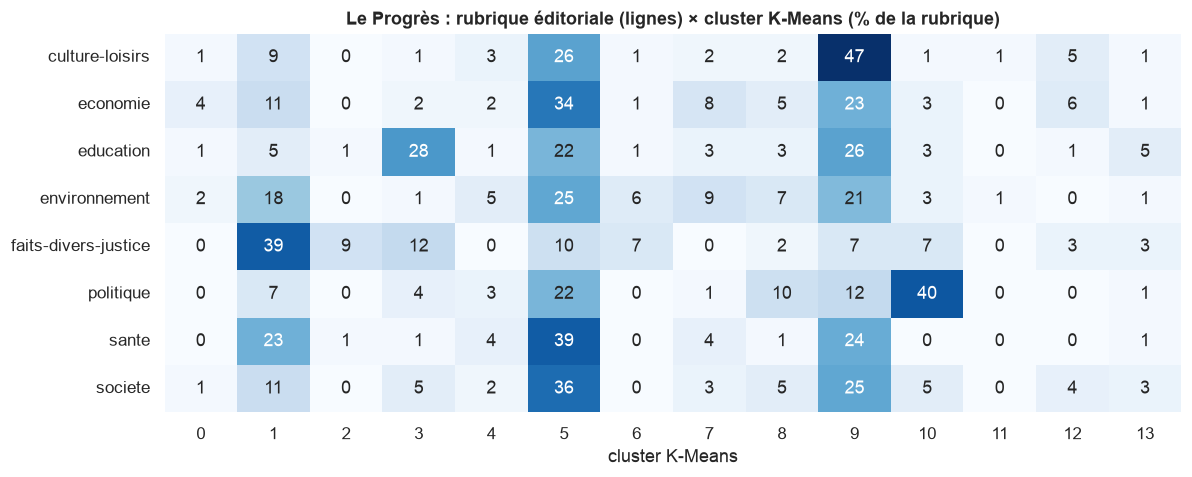

In [9]:
# Les rubriques du Progrès se répartissent-elles de façon cohérente dans les clusters K-Means (modèle retenu) ? (% de chaque rubrique, lignes)
lp = df[df.media_name == "Le Progrès"]
main_sec = lp["section"].value_counts().head(8).index
x = pd.crosstab(lp[lp.section.isin(main_sec)]["section"], lp[lp.section.isin(main_sec)]["km"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(x.round(0), annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax); ax.set(title="Le Progrès : rubrique éditoriale (lignes) × cluster K-Means (% de la rubrique)", xlabel="cluster K-Means", ylabel="")
plt.tight_layout(); fig.savefig(FIG / "05_rubriques_vs_kmeans.png", bbox_inches="tight"); plt.show()

In [10]:
# Résultat exploité aux étapes 6 et 7
out = df[["article_id", "media_name", "date", "week_start", "km", "km_label", "lda", "lda_label", "lda_prob"]]
out.to_parquet(ROOT / "data" / "processed" / "article_topics.parquet", index=False)
print(f"{len(out):,} titres → data/processed/article_topics.parquet")

4,929 titres → data/processed/article_topics.parquet


## 6. Synthèse de l'étape 5

- **TF-IDF** : matrice 4 929 titres × 2 528 termes, densité 0,22 % (≈ 5,5 termes par titre). La représentation est extrêmement creuse : deux titres sur le même sujet partagent peu de mots.
- **K-Means (LSA 100 dimensions, 22 % de variance expliquée)** : la silhouette est faible (0,03 à 0,16) et **croît mécaniquement avec k** (petits groupes), la stabilité entre graines est modeste (ARI 0,22 à 0,54), l'accord avec les rubriques du Progrès culmine à AMI ≈ 0,12. On retient **k = 14** : c'est, parmi les k modestes, le meilleur accord avec les rubriques et des groupes lisibles ; à k = 12 un groupe fourre-tout absorbe 42 % du corpus. Sa stabilité (ARI 0,25) est un point faible à signaler.
- **LDA** : la cohérence NPMI est négative pour tous les k (−0,17 à −0,32) et la perplexité de test augmente avec k : des titres de ≈ 5 mots ne contiennent pas assez de co-occurrences pour un modèle de thèmes probabiliste. On retient **k = 6** (meilleure cohérence). Deux des six thèmes restent mixtes (« mobilisation, grèves, festivals » ; « politique municipale, violences, lycées »). 79,5 % des titres ont un thème dominant de probabilité > 0,5.
- **Comparaison** : les deux partitions **se recoupent très peu** (AMI 0,085, ARI 0,033). Contre les rubriques du Progrès, K-Means (AMI 0,119) fait nettement mieux que LDA (0,032). **K-Means est donc le modèle retenu pour les étapes 6 et 7**, LDA étant conservé comme comparaison et pour illustrer la limite des modèles probabilistes sur textes courts.
- **Thèmes réellement identifiés (K-Means)** : travaux et circulation ; accidents, incendies et faits divers (888 titres) ; violences et justice pénale ; **mobilisation lycéenne et manifestations (427)** ; vigilance météo régionale ; vie locale (917) ; incendies de grande ampleur ; sécheresse et agriculture ; finances métropolitaines ; politique municipale et élections ; météo locale ; Beaujolais et vendanges ; fusillades à Villeurbanne ; culture et festivals. Les groupes 5 (917), 9 (1 002) et 1 (888) restent larges et partiellement fourre-tout.
- **Limites à écrire dans le rapport** : pas de vérité terrain (les libellés sont notre lecture des termes) ; instabilité de K-Means entre graines ; titres courts ; clusters définis par des mots, pas par des événements (un même événement peut se retrouver dans plusieurs clusters). **BFM Lyon, BERTopic et les embeddings de phrases** n'ont pas été testés : ils demandent PyTorch et le téléchargement d'un modèle de plusieurs centaines de Mo ; ce sont les pistes naturelles pour améliorer le rappel sémantique.
- **Conséquence pour l'étape 6** : les clusters servent de grille de lecture secondaire ; l'analyse d'émergence reposera d'abord sur les **mots et expressions**, plus robustes que ces regroupements instables.